In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("../data/raw/creditcard.csv")

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.shape

(284807, 31)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

### Class column
 - identify if the transaction is fraudulent (0 == NO/ 1 == Yes)
 - "284315" Normal Transaction and "492" Fraudulent transaction.

In [8]:

print(df["Class"].value_counts())
print("Total Transactions: ",np.sum(df["Class"].value_counts()))

Class
0    284315
1       492
Name: count, dtype: int64
Total Transactions:  284807


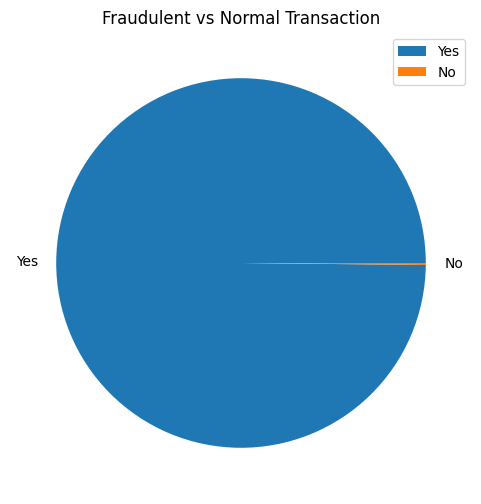

In [9]:
plt.figure(figsize = (6,6))
plt.pie([np.sum(df["Class"] == 0), np.sum(df["Class"] == 1)], labels = ["Yes","No"] )
plt.title("Fraudulent vs Normal Transaction")
plt.legend()

plt.show()

In [10]:
# There is no Null values in the dataset
print("if there is any Null values: ",df.isnull().values.any())
print("Null values in each column:",df.isna().value_counts())

if there is any Null values:  False
Null values in each column: Time   V1     V2     V3     V4     V5     V6     V7     V8     V9     V10    V11    V12    V13    V14    V15    V16    V17    V18    V19    V20    V21    V22    V23    V24    V25    V26    V27    V28    Amount  Class
False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False  False   False    284807
Name: count, dtype: int64


## Basis statistical description

In [11]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [12]:
print(df["Class"][df["Amount"] == df["Amount"].max()])
print(df["Class"][df["Amount"] == df["Amount"].min()])

274771    0
Name: Class, dtype: int64
383       0
514       0
534       0
541       1
575       0
         ..
283719    0
283782    0
283949    0
284085    0
284770    0
Name: Class, Length: 1825, dtype: int64


In [13]:
print("Total number of $0 transactions:",np.sum(df["Amount"]== 0))
print("Normal vs Fraudulent in $0 transactions:",
    df["Class"][df["Amount"]==0].value_counts()
)
print("Percentage of total fraudulent transaction that occurred in $0 transactions:", 27/np.sum(df["Class"] == 1)*100)

Total number of $0 transactions: 1825
Normal vs Fraudulent in $0 transactions: Class
0    1798
1      27
Name: count, dtype: int64
Percentage of total fraudulent transaction that occurred in $0 transactions: 5.487804878048781


## Zero Dollars Transactions Summary
- There were 1825 $0 transactions
- 27 of those transactions were fraudulent transactions
- 5.5 % of total fraudulent transactions occurred in $0 transaction

## Duplicate values analysis

In [14]:
duplicates = df[df.duplicated(keep = False)]
print("total duplicates rows:",len(duplicates))

total duplicates rows: 1854


In [15]:
print("Percentage of duplicated rows by class: ",duplicates["Class"].value_counts(normalize=True).mul(100).round(4))

Percentage of duplicated rows by class:  Class
0    98.274
1     1.726
Name: proportion, dtype: float64


In [16]:
# Duplicate consistency check

feature_cols = [col for col in df.columns if col != "Class"]

duplicate_rows = df[df.duplicated(keep = False)]

duplicate_label_check = (duplicate_rows.groupby(feature_cols)["Class"].nunique())

consistent = (duplicate_label_check == 1).sum()
conflicting = (duplicate_label_check > 1).sum()

print("Duplicate groups with consistent labels:", consistent)
print("Duplicate groups with conflicting labels:", conflicting)

Duplicate groups with consistent labels: 773
Duplicate groups with conflicting labels: 0


In [17]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
after = len(df)

print("Rows before  removal duplicates: ", before)
print("Rows after removal:", after)
print("Rows removed: ", before - after)
print("New Dataset shape: ",df.shape)

Rows before  removal duplicates:  284807
Rows after removal: 283726
Rows removed:  1081
New Dataset shape:  (283726, 31)


In [18]:
print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


## Outlier Analysis

In [19]:
print("Transaction amount stats summary: ")
display(df["Amount"].describe())

Transaction amount stats summary: 


count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

In [20]:
q1 = df["Amount"].quantile(0.25)
q3 = df["Amount"].quantile(0.75)

iqr = q3 - q1

In [21]:
print("Q1: ", q1)
print("Q3: ", q3)
print("IQR: ",iqr.round(3))

Q1:  5.6
Q3:  77.51
IQR:  71.91


In [22]:
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Lower Bound: ", lower_bound.round(4))
print("Upper Bound: ", upper_bound.round(4))

total_outliers = df[(df["Amount"] > upper_bound) | (df["Amount"] < lower_bound)]
print("Total number of outliers in the dataset: ", len(total_outliers))
print("Percentage of outliers: ", round((len(total_outliers)/len(df))*100, 4), "%")

Lower Bound:  -102.265
Upper Bound:  185.375
Total number of outliers in the dataset:  31685
Percentage of outliers:  11.1675 %


* any amount lower than lower bound (-102.265) and above upper bound (185.375) are outliers 

In [23]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


### Most of the fraudulent transactions ranges between 0 - 5k

<Axes: xlabel='Class', ylabel='Amount'>

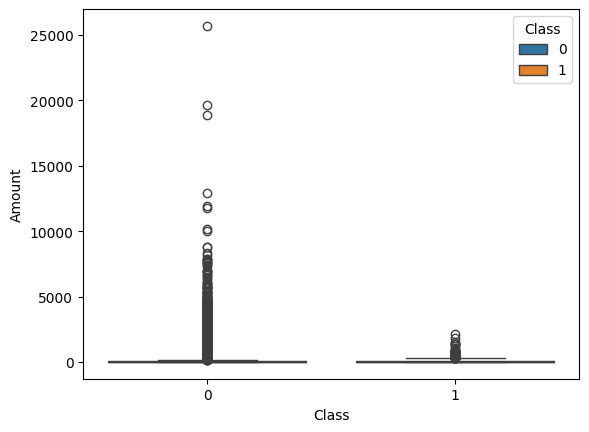

In [24]:
sns.boxplot(data = df, x = "Class", y = "Amount", hue = "Class")

<Axes: xlabel='Amount', ylabel='Class'>

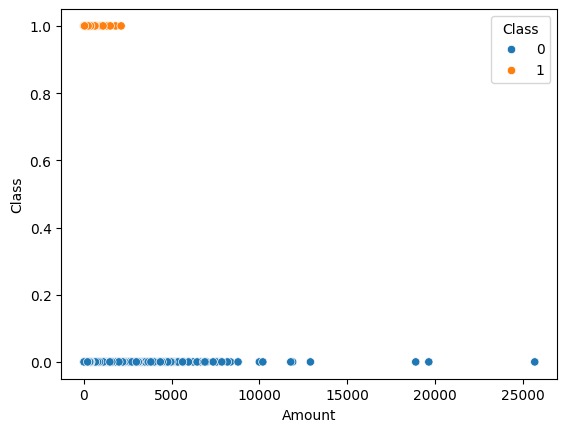

In [25]:
sns.scatterplot(data = df, x=df["Amount"], y=df["Class"], hue = df["Class"])

## Feature engineering

In [26]:
df["Hours"] = ((df["Time"]//3600) % 24).astype(int)
print("Hours feature created: ")
print("Min hour: ", df["Hours"].min())
print("Max hour: ", df["Hours"].max())

Hours feature created: 
Min hour:  0
Max hour:  23


In [27]:
fraud_by_hours = (df[df["Class"] == 1].groupby("Hours").size().sort_index())

In [28]:
fraud_by_hours

Hours
0      6
1     10
2     48
3     17
4     23
5     11
6      9
7     23
8      9
9     16
10     8
11    53
12    17
13    17
14    23
15    26
16    22
17    28
18    28
19    19
20    18
21    16
22     9
23    17
dtype: int64

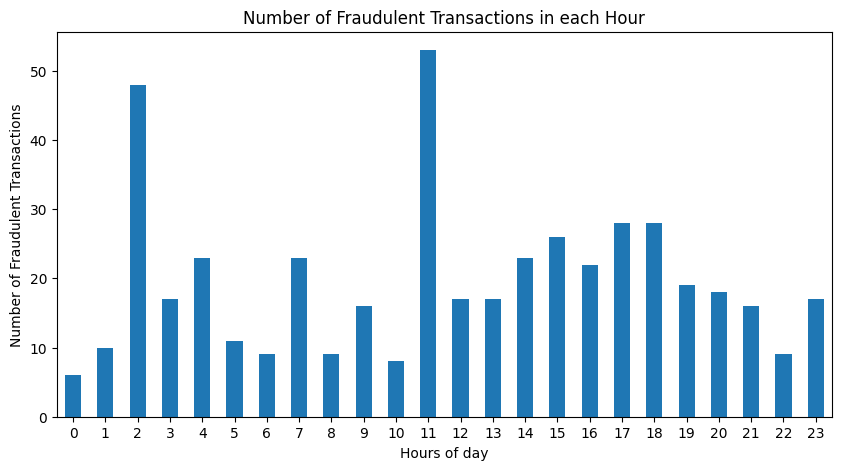

In [60]:
plt.figure(figsize = (10,5))
fraud_by_hours.plot(kind="bar")
plt.xlabel("Hours of day")
plt.ylabel("Number of Fraudulent Transactions")
plt.title("Number of Fraudulent Transactions in each Hour")
plt.xticks(rotation = 0)
plt.show()

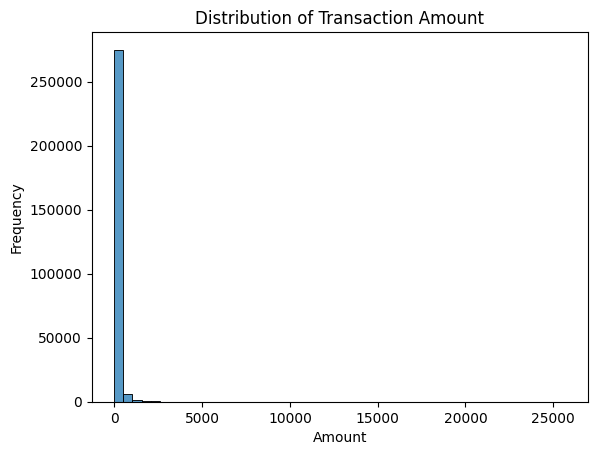

In [38]:
sns.histplot(data = df, x = "Amount", bins = 50)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.show()

## Skewed Amount

* Due to high number of small transactions, the data is highly skewed towards the left
* Taking log of the amount can fix the skewness of the transactions

In [33]:
df["LogAmount"] = np.log1p(df["Amount"])

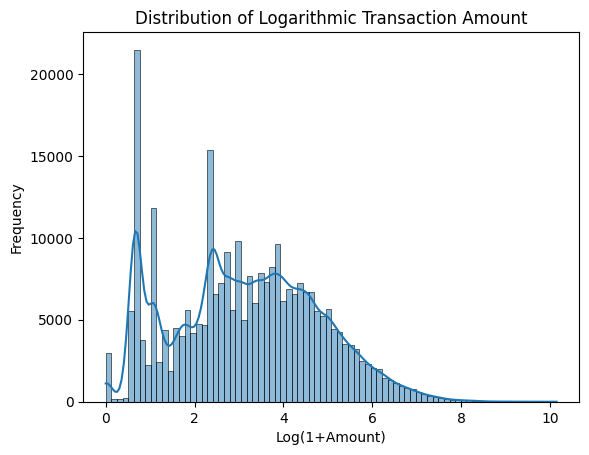

In [40]:
sns.histplot(data = df, x = "LogAmount", bins = 80, kde = True)
plt.title("Distribution of Logarithmic Transaction Amount")
plt.xlabel("Log(1+Amount)")
plt.ylabel("Frequency")
plt.show()

In [43]:
print(df[["Amount", "LogAmount"]].describe())

              Amount      LogAmount
count  283726.000000  283726.000000
mean       88.472687       3.153760
std       250.399437       1.657080
min         0.000000       0.000000
25%         5.600000       1.887070
50%        22.000000       3.135494
75%        77.510000       4.363226
max     25691.160000      10.153941


In [45]:
pca_features = [f"V{i}" for i in range(1,29)]

display(df[pca_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995
V10,283726.0,-0.001441,1.076407,-24.588262,-0.535578,-0.093237,0.453619,23.745136


In [51]:
correlation = df.corr(numeric_only = True)["Class"].drop("Class").sort_values(key=abs, ascending=False)


display(correlation)

V17         -0.313498
V14         -0.293375
V12         -0.250711
V10         -0.206971
V16         -0.187186
V3          -0.182322
V7          -0.172347
V11          0.149067
V4           0.129326
V18         -0.105340
V1          -0.094486
V9          -0.094021
V5          -0.087812
V2           0.084624
V6          -0.043915
V19          0.033631
V8           0.033068
V21          0.026357
V27          0.021892
V20          0.021486
Hours       -0.016740
Time        -0.012359
V28          0.009682
LogAmount   -0.007798
V24         -0.007210
V23         -0.006333
Amount       0.005777
V22          0.004887
V26          0.004265
V13         -0.003897
V15         -0.003300
V25          0.003202
Name: Class, dtype: float64

In [50]:
print("New Features: ")
print(["Hours","LogAmount"])

print("\nDataset Shape: ", df.shape)

New Features: 
['Hours', 'LogAmount']

Dataset Shape:  (283726, 33)


### Analyzing Fraud Pattern by Hours

In [61]:
hour_analysis = df.groupby("Hours")["Class"].agg(TotalTransaction = "count", FraudCount = "sum")

hour_analysis["FraudPercent"] = (hour_analysis["FraudCount"]/hour_analysis["TotalTransaction"]) * 100

display(hour_analysis)

,TotalTransaction,FraudCount,FraudPercent
Hours,,,
0,7647,6,0.078462
1,4208,10,0.237643
2,3308,48,1.451028
3,3487,17,0.487525
4,2204,23,1.043557
5,2988,11,0.368139
6,4082,9,0.220480
7,7233,23,0.317987
8,10232,9,0.087959


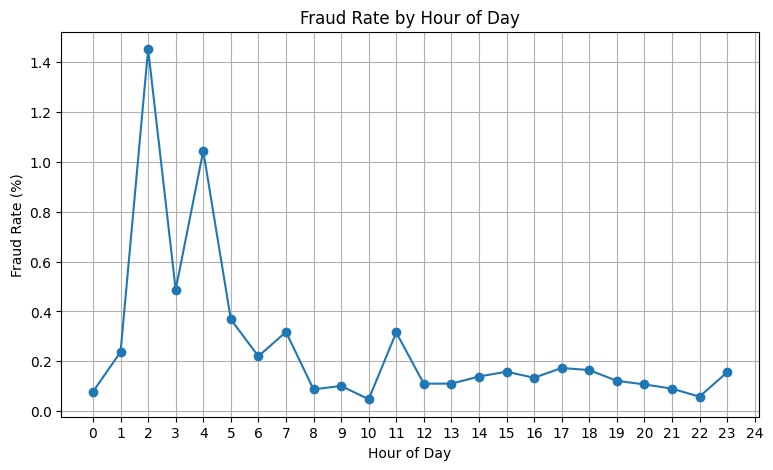

In [72]:
plt.figure(figsize = (9,5))
plt.plot(hour_analysis.index, hour_analysis["FraudPercent"], marker = "o", )
plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(25))
plt.grid(True)
plt.show()

In [77]:
print("Final Rows: ", df.shape[0])
print("Final Columns: ", df.shape[1])

print("Final Shape: ", df.shape)
print("\nClass Distribution (Fraudulent: 0, Normal: 1): ", df["Class"].value_counts())

Final Rows:  283726
Final Columns:  33
Final Shape:  (283726, 33)

Class Distribution (Fraudulent: 0, Normal: 1):  Class
0    283253
1       473
Name: count, dtype: int64


In [78]:
df.to_csv('feature.csv', index = False)